In [1]:
# configuration
import glob, os, struct, time, math, json, random
import numpy as np, pandas as pd, torch
import torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT_DIR = "/kaggle/working/results"; os.makedirs(OUT_DIR, exist_ok=True)
print("Device:", device)
if device.type == "cuda": print(torch.cuda.get_device_name(0))

Device: cuda
Tesla T4


(60000, 28, 28) (60000,) (10000, 28, 28) (10000,)
torch.Size([54000, 1, 28, 28]) torch.Size([6000, 1, 28, 28]) torch.Size([10000, 1, 28, 28]) | min/max : 0.0 1.0


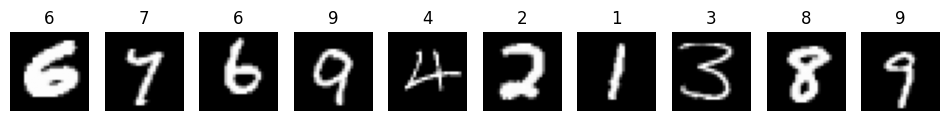

In [2]:
# lecture de MNIST, découpage, contrôle
def find(name):
    hits = [p for p in glob.glob(f"/kaggle/input/**/{name}", recursive=True) if os.path.isfile(p)]
    assert hits, f"{name} introuvable : ajoute le dataset MNIST avec Add Input"
    return hits[0]

def read_idx_images(path):
    with open(path, "rb") as f:
        magic, n, rows, cols = struct.unpack(">IIII", f.read(16))
        return np.frombuffer(f.read(), dtype=np.uint8).reshape(n, rows, cols)

def read_idx_labels(path):
    with open(path, "rb") as f:
        magic, n = struct.unpack(">II", f.read(8))
        return np.frombuffer(f.read(), dtype=np.uint8)

X_train = read_idx_images(find("train-images-idx3-ubyte")); y_train = read_idx_labels(find("train-labels-idx1-ubyte"))
X_test  = read_idx_images(find("t10k-images-idx3-ubyte"));  y_test  = read_idx_labels(find("t10k-labels-idx1-ubyte"))
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)      # (60000, 28, 28) (60000,) (10000, 28, 28) (10000,)

perm = torch.randperm(60000, generator=torch.Generator().manual_seed(SEED)).tolist()
tr_idx, va_idx = perm[:54000], perm[54000:]                          # même découpage que les labs précédents
to_x = lambda X: torch.from_numpy(X.copy()).float().div(255).unsqueeze(1)   # pixels dans [0, 1]
to_y = lambda y: torch.from_numpy(y.astype(np.int64))
Xtr, ytr = to_x(X_train[tr_idx]).to(device), to_y(y_train[tr_idx]).to(device)
Xva, yva = to_x(X_train[va_idx]).to(device), to_y(y_train[va_idx]).to(device)
Xte, yte = to_x(X_test).to(device),          to_y(y_test).to(device)
print(Xtr.shape, Xva.shape, Xte.shape, "| min/max :", Xtr.min().item(), Xtr.max().item())

fig, ax = plt.subplots(1, 10, figsize=(12, 1.6))
for i, a in enumerate(ax):
    a.imshow(Xtr[i, 0].cpu(), cmap="gray"); a.set_title(int(ytr[i])); a.axis("off")
plt.show()

In [5]:
# auto-encodeur et fonctions
class AE(nn.Module):
    def __init__(self, latent=32, hidden=(512, 256)):
        super().__init__()
        h1, h2 = hidden
        self.enc = nn.Sequential(nn.Flatten(), nn.Linear(784, h1), nn.ReLU(),
                                 nn.Linear(h1, h2), nn.ReLU(), nn.Linear(h2, latent))
        self.dec = nn.Sequential(nn.Linear(latent, h2), nn.ReLU(),
                                 nn.Linear(h2, h1), nn.ReLU(), nn.Linear(h1, 784))
    def forward(self, x):
        z = self.enc(x)
        return self.dec(z).view(-1, 1, 28, 28), z            # logits et code latent

def recon_loss(logits, x):    # entropie croisée binaire : somme sur les pixels, moyenne sur les images
    return F.binary_cross_entropy_with_logits(logits, x, reduction="sum") / x.size(0)

def batches(X, bs, shuffle):
    idx = torch.randperm(len(X), device=device) if shuffle else torch.arange(len(X), device=device)
    for i in range(0, len(X), bs):
        yield X[idx[i:i + bs]]

@torch.no_grad()
def eval_ae(model, X, bs=1000):
    model.eval(); bce, mse = 0.0, 0.0
    for x in batches(X, bs, False):
        logits, _ = model(x)
        bce += recon_loss(logits, x).item() * len(x)
        mse += F.mse_loss(torch.sigmoid(logits), x).item() * len(x)
    return bce / len(X), mse / len(X)

def fit_ae(latent, lr, epochs=15, bs=128, seed=SEED):
    torch.manual_seed(seed)
    model = AE(latent).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {"train": [], "val": [], "val_mse": []}
    torch.cuda.synchronize(); t0 = time.time()
    for ep in range(epochs):
        model.train(); run = 0.0
        for x in batches(Xtr, bs, True):
            logits, _ = model(x); loss = recon_loss(logits, x)
            opt.zero_grad(); loss.backward(); opt.step()
            run += loss.item() * len(x)
        v, vm = eval_ae(model, Xva)
        hist["train"].append(run / len(Xtr)); hist["val"].append(v); hist["val_mse"].append(vm)
    torch.cuda.synchronize()
    return model, hist, time.time() - t0

print("paramètres (latent=32) :", sum(p.numel() for p in AE(32).parameters()))

paramètres (latent=32) : 1083696


In [6]:
# recherche d'hyperparamètres de l'AE
LATENTS, LRS = [2, 8, 32], [1e-3, 3e-3]
ae_runs, rows = {}, []
for lat in LATENTS:
    for lr in LRS:
        model, hist, t = fit_ae(lat, lr)
        ae_runs[(lat, lr)] = (model, hist)
        rows.append({"latent": lat, "lr": lr, "val_BCE": hist["val"][-1],
                     "val_MSE": hist["val_mse"][-1], "temps_s": t})
        print(f"latent={lat:2d} lr={lr:.0e} | val BCE {hist['val'][-1]:.2f} | val MSE {hist['val_mse'][-1]:.5f} | {t:.0f} s")
ae_grid = pd.DataFrame(rows)
ae_grid.round(5).to_csv(f"{OUT_DIR}/ae_grid.csv", index=False)
display(ae_grid.round(5))

latent= 2 lr=1e-03 | val BCE 133.16 | val MSE 0.03610 | 15 s
latent= 2 lr=3e-03 | val BCE 134.30 | val MSE 0.03662 | 14 s
latent= 8 lr=1e-03 | val BCE 85.63 | val MSE 0.01548 | 14 s
latent= 8 lr=3e-03 | val BCE 85.02 | val MSE 0.01517 | 14 s
latent=32 lr=1e-03 | val BCE 61.71 | val MSE 0.00571 | 14 s
latent=32 lr=3e-03 | val BCE 62.11 | val MSE 0.00590 | 14 s


,latent,lr,val_BCE,val_MSE,temps_s
0,2,0.001,133.16201,0.03610,14.54625
1,2,0.003,134.30225,0.03662,13.89014
2,8,0.001,85.63069,0.01548,14.02803
3,8,0.003,85.01953,0.01517,14.03708
4,32,0.001,61.70647,0.00571,13.83135
5,32,0.003,62.10759,0.00590,14.15794


AE retenu : latent=32, lr=1e-03 | test BCE 61.12 | test MSE 0.00557


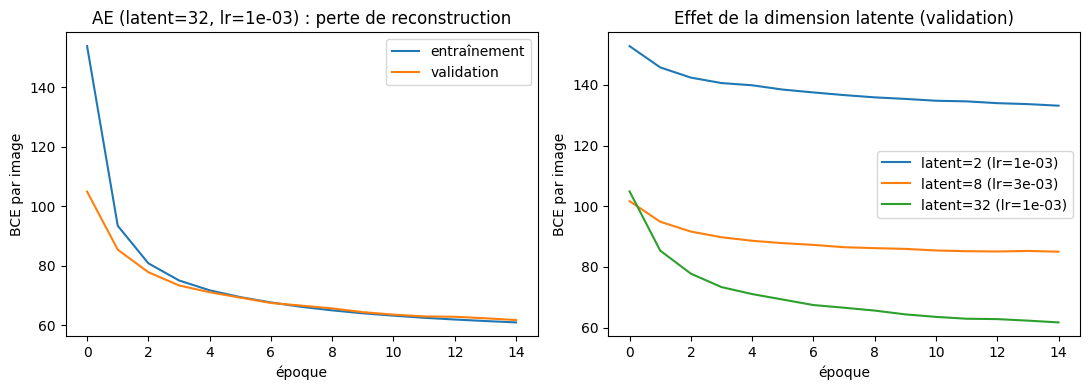

In [7]:
# modèle retenu, test, courbes
best = min(rows, key=lambda r: r["val_BCE"])
LAT_AE, LR_AE = best["latent"], best["lr"]
model_ae, hist_ae = ae_runs[(LAT_AE, LR_AE)]
te_bce, te_mse = eval_ae(model_ae, Xte)
print(f"AE retenu : latent={LAT_AE}, lr={LR_AE:.0e} | test BCE {te_bce:.2f} | test MSE {te_mse:.5f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist_ae["train"], label="entraînement"); ax[0].plot(hist_ae["val"], label="validation")
ax[0].set(title=f"AE (latent={LAT_AE}, lr={LR_AE:.0e}) : perte de reconstruction", xlabel="époque", ylabel="BCE par image")
ax[0].legend()
for lat in LATENTS:
    r = min([r for r in rows if r["latent"] == lat], key=lambda r: r["val_BCE"])
    ax[1].plot(ae_runs[(lat, r["lr"])][1]["val"], label=f"latent={lat} (lr={r['lr']:.0e})")
ax[1].set(title="Effet de la dimension latente (validation)", xlabel="époque", ylabel="BCE par image"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/ae_curves.png", dpi=150); plt.show()

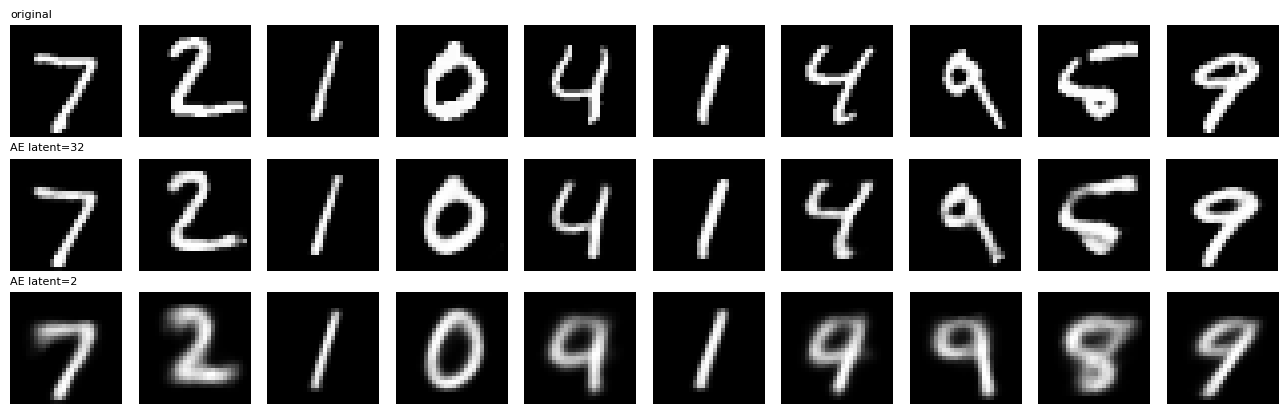

In [8]:
# reconstructions et sauvegarde
lr2 = min([r for r in rows if r["latent"] == 2], key=lambda r: r["val_BCE"])["lr"]
model_ae2 = ae_runs[(2, lr2)][0]                  # AE à 2 dimensions (pour l'espace latent)

@torch.no_grad()
def show_recon(models, names, n=10):
    fig, ax = plt.subplots(1 + len(models), n, figsize=(1.3 * n, 1.4 * (1 + len(models))))
    for i in range(n):
        ax[0, i].imshow(Xte[i, 0].cpu(), cmap="gray"); ax[0, i].axis("off")
        for k, m in enumerate(models):
            m.eval(); ax[k + 1, i].imshow(torch.sigmoid(m(Xte[i:i+1])[0])[0, 0].cpu(), cmap="gray"); ax[k + 1, i].axis("off")
    ax[0, 0].set_title("original", fontsize=8, loc="left")
    for k, nm in enumerate(names): ax[k + 1, 0].set_title(nm, fontsize=8, loc="left")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/ae_reconstructions.png", dpi=150); plt.show()

show_recon([model_ae, model_ae2], [f"AE latent={LAT_AE}", "AE latent=2"])

e2 = eval_ae(model_ae2, Xte)
json.dump({"grid": rows, "retenu": {"latent": LAT_AE, "lr": LR_AE, "test_BCE": te_bce, "test_MSE": te_mse},
           "latent2": {"lr": lr2, "test_BCE": e2[0], "test_MSE": e2[1]}},
          open(f"{OUT_DIR}/results_ae.json", "w"), indent=1)
torch.save(model_ae.state_dict(), f"{OUT_DIR}/ae_best.pt"); torch.save(model_ae2.state_dict(), f"{OUT_DIR}/ae_latent2.pt")

In [9]:
# VAE et fonctions
class VAE(nn.Module):
    def __init__(self, latent=32, hidden=(512, 256)):
        super().__init__()
        h1, h2 = hidden
        self.enc = nn.Sequential(nn.Flatten(), nn.Linear(784, h1), nn.ReLU(), nn.Linear(h1, h2), nn.ReLU())
        self.mu, self.logvar = nn.Linear(h2, latent), nn.Linear(h2, latent)
        self.dec = nn.Sequential(nn.Linear(latent, h2), nn.ReLU(), nn.Linear(h2, h1), nn.ReLU(), nn.Linear(h1, 784))
    def encode(self, x):
        h = self.enc(x); return self.mu(h), self.logvar(h)
    def forward(self, x):                                           # reparamétrisation : z = mu + sigma * epsilon
        mu, logvar = self.encode(x)
        z = mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)
        return self.dec(z).view(-1, 1, 28, 28), mu, logvar

def kl_div(mu, logvar):     # KL(q(z|x) || N(0, I)) : somme sur les dimensions, moyenne sur les images
    return (-0.5 * (1 + logvar - mu.pow(2) - logvar.exp()).sum(dim=1)).mean()

@torch.no_grad()
def eval_vae(model, X, bs=1000):
    model.eval(); rec = kl = mse = 0.0
    for x in batches(X, bs, False):
        logits, mu, logvar = model(x)
        rec += recon_loss(logits, x).item() * len(x); kl += kl_div(mu, logvar).item() * len(x)
        mse += F.mse_loss(torch.sigmoid(logits), x).item() * len(x)
    n = len(X); return rec / n, kl / n, mse / n

def fit_vae(latent, lr, beta=1.0, epochs=15, bs=128, seed=SEED):
    torch.manual_seed(seed)
    model = VAE(latent).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {k: [] for k in ["train_rec", "train_kl", "val_rec", "val_kl", "val_elbo"]}
    torch.cuda.synchronize(); t0 = time.time()
    for ep in range(epochs):
        model.train(); r_sum = k_sum = 0.0
        for x in batches(Xtr, bs, True):
            logits, mu, logvar = model(x)
            rec, kl = recon_loss(logits, x), kl_div(mu, logvar)
            loss = rec + beta * kl
            opt.zero_grad(); loss.backward(); opt.step()
            r_sum += rec.item() * len(x); k_sum += kl.item() * len(x)
        v_rec, v_kl, _ = eval_vae(model, Xva)
        hist["train_rec"].append(r_sum / len(Xtr)); hist["train_kl"].append(k_sum / len(Xtr))
        hist["val_rec"].append(v_rec); hist["val_kl"].append(v_kl); hist["val_elbo"].append(v_rec + v_kl)
    torch.cuda.synchronize()
    return model, hist, time.time() - t0

@torch.no_grad()
def active_units(model, X, bs=1000):                 # dimensions dont la moyenne varie avec l'image (variance > 0.01)
    model.eval(); mus = torch.cat([model.encode(x)[0] for x in batches(X, bs, False)])
    return int((mus.var(dim=0) > 0.01).sum().item())

print("paramètres (latent=32) :", sum(p.numel() for p in VAE(32).parameters()))

paramètres (latent=32) : 1091920


In [10]:
# recherche d'hyperparamètres du VAE
vae_runs, vrows = {}, []
for lat in [2, 8, 32]:
    for lr in [1e-3, 3e-3]:
        model, hist, t = fit_vae(lat, lr)
        vae_runs[(lat, lr)] = (model, hist)
        vrows.append({"latent": lat, "lr": lr, "val_rec": hist["val_rec"][-1], "val_KL": hist["val_kl"][-1],
                      "val_ELBO": hist["val_elbo"][-1], "temps_s": t})
        print(f"latent={lat:2d} lr={lr:.0e} | rec {hist['val_rec'][-1]:.2f} | KL {hist['val_kl'][-1]:.2f} "
              f"| ELBO {hist['val_elbo'][-1]:.2f} | {t:.0f} s")
vae_grid = pd.DataFrame(vrows)
vae_grid.round(4).to_csv(f"{OUT_DIR}/vae_grid.csv", index=False)
display(vae_grid.round(4))

latent= 2 lr=1e-03 | rec 137.07 | KL 6.52 | ELBO 143.59 | 20 s
latent= 2 lr=3e-03 | rec 137.92 | KL 6.57 | ELBO 144.50 | 19 s
latent= 8 lr=1e-03 | rec 90.48 | KL 16.36 | ELBO 106.84 | 19 s
latent= 8 lr=3e-03 | rec 91.97 | KL 16.19 | ELBO 108.17 | 19 s
latent=32 lr=1e-03 | rec 84.52 | KL 18.92 | ELBO 103.44 | 19 s
latent=32 lr=3e-03 | rec 91.63 | KL 16.94 | ELBO 108.57 | 19 s


,latent,lr,val_rec,val_KL,val_ELBO,temps_s
0,2,0.001,137.0693,6.5171,143.5865,19.5650
1,2,0.003,137.9243,6.5728,144.4971,19.2440
2,8,0.001,90.4807,16.3583,106.8390,19.2081
3,8,0.003,91.9747,16.1908,108.1655,19.2398
4,32,0.001,84.5195,18.9163,103.4358,19.4034
5,32,0.003,91.6287,16.9432,108.5719,19.3427


VAE retenu : latent=32, lr=1e-03 | test : reconstruction 83.45 | KL 18.95 | ELBO 102.40 | MSE 0.01477 | dimensions actives 11/32


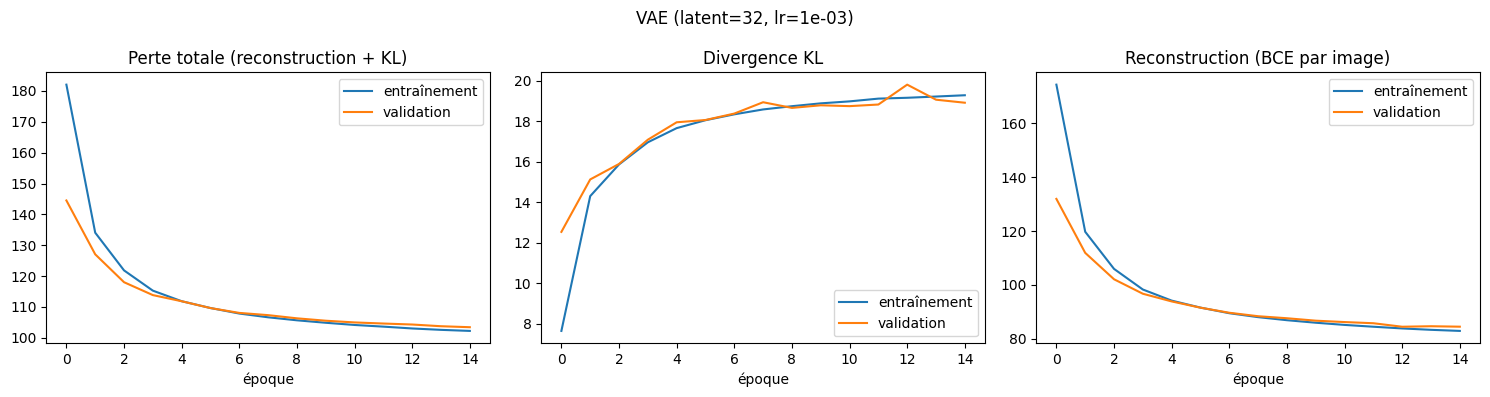

In [11]:
# VAE retenu, test, courbes
bv = min(vrows, key=lambda r: r["val_ELBO"])
LAT_VAE, LR_VAE = bv["latent"], bv["lr"]
model_vae, hist_v = vae_runs[(LAT_VAE, LR_VAE)]
te_rec, te_kl, te_mse = eval_vae(model_vae, Xte)
n_act = active_units(model_vae, Xva)
print(f"VAE retenu : latent={LAT_VAE}, lr={LR_VAE:.0e} | test : reconstruction {te_rec:.2f} | KL {te_kl:.2f} "
      f"| ELBO {te_rec + te_kl:.2f} | MSE {te_mse:.5f} | dimensions actives {n_act}/{LAT_VAE}")

h = hist_v
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(np.array(h["train_rec"]) + np.array(h["train_kl"]), label="entraînement"); ax[0].plot(h["val_elbo"], label="validation")
ax[0].set(title="Perte totale (reconstruction + KL)", xlabel="époque"); ax[0].legend()
ax[1].plot(h["train_kl"], label="entraînement"); ax[1].plot(h["val_kl"], label="validation")
ax[1].set(title="Divergence KL", xlabel="époque"); ax[1].legend()
ax[2].plot(h["train_rec"], label="entraînement"); ax[2].plot(h["val_rec"], label="validation")
ax[2].set(title="Reconstruction (BCE par image)", xlabel="époque"); ax[2].legend()
plt.suptitle(f"VAE (latent={LAT_VAE}, lr={LR_VAE:.0e})"); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/vae_curves.png", dpi=150); plt.show()

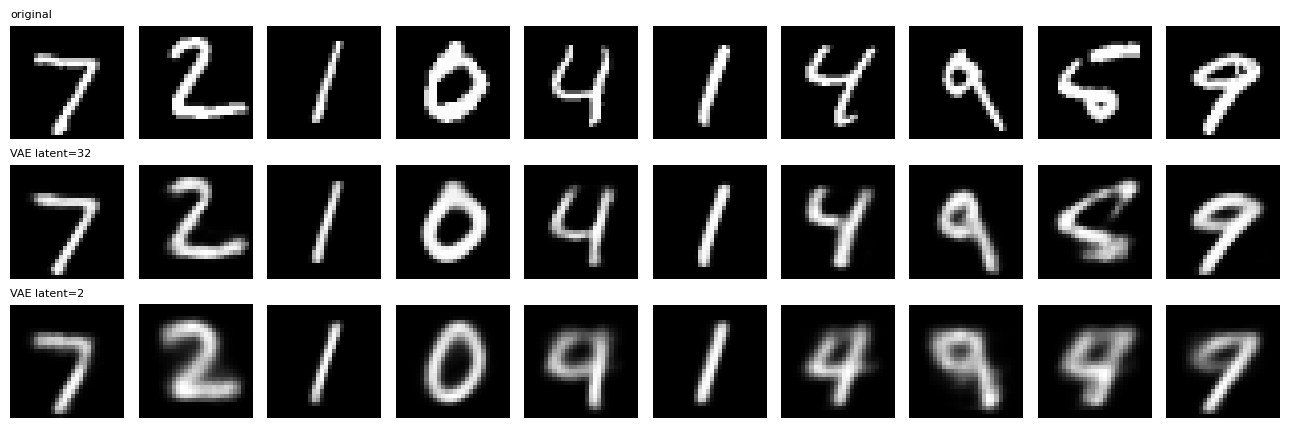

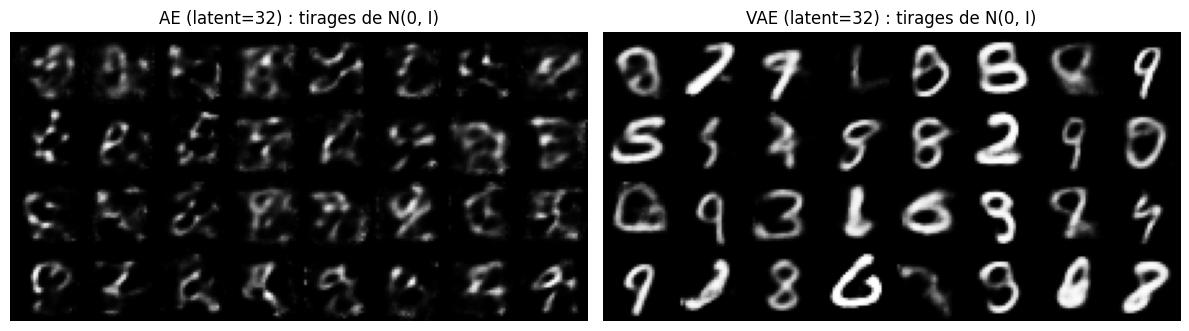

In [12]:
# reconstructions, génération, sauvegarde
lr2v = min([r for r in vrows if r["latent"] == 2], key=lambda r: r["val_ELBO"])["lr"]
model_vae2 = vae_runs[(2, lr2v)][0]                      # VAE à 2 dimensions (pour l'espace latent)

@torch.no_grad()
def vae_recon(m, x): m.eval(); return torch.sigmoid(m.dec(m.encode(x)[0])).view(-1, 1, 28, 28)

def to_grid(imgs, ncol=8):
    nr = math.ceil(len(imgs) / ncol); canvas = torch.zeros(nr * 28, ncol * 28)
    for i, im in enumerate(imgs):
        r, c = divmod(i, ncol); canvas[r*28:(r+1)*28, c*28:(c+1)*28] = im[0].cpu()
    return canvas

# Reconstructions
fig, ax = plt.subplots(3, 10, figsize=(13, 4.4))
rows_ = [("original", Xte[:10]), (f"VAE latent={LAT_VAE}", vae_recon(model_vae, Xte[:10])), ("VAE latent=2", vae_recon(model_vae2, Xte[:10]))]
for r, (name, imgs) in enumerate(rows_):
    for i in range(10): ax[r, i].imshow(imgs[i, 0].detach().cpu(), cmap="gray"); ax[r, i].axis("off")
    ax[r, 0].set_title(name, fontsize=8, loc="left")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/vae_reconstructions.png", dpi=150); plt.show()

# Génération : chiffres tirés de N(0, I), décodés par l'AE puis par le VAE
torch.manual_seed(SEED)
with torch.no_grad():
    z = torch.randn(32, LAT_AE, device=device)
    ae_gen = torch.sigmoid(model_ae.dec(z)).view(-1, 1, 28, 28)
    zv = torch.randn(32, LAT_VAE, device=device)
    vae_gen = torch.sigmoid(model_vae.dec(zv)).view(-1, 1, 28, 28)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].imshow(to_grid(ae_gen), cmap="gray"); ax[0].set_title(f"AE (latent={LAT_AE}) : tirages de N(0, I)"); ax[0].axis("off")
ax[1].imshow(to_grid(vae_gen), cmap="gray"); ax[1].set_title(f"VAE (latent={LAT_VAE}) : tirages de N(0, I)"); ax[1].axis("off")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/generation_ae_vs_vae.png", dpi=150); plt.show()

e2 = eval_vae(model_vae2, Xte)
json.dump({"grid": vrows,
           "retenu": {"latent": LAT_VAE, "lr": LR_VAE, "test_rec": te_rec, "test_KL": te_kl, "test_ELBO": te_rec + te_kl,
                      "test_MSE": te_mse, "dimensions_actives": n_act},
           "latent2": {"lr": lr2v, "test_rec": e2[0], "test_KL": e2[1], "test_ELBO": e2[0] + e2[1], "test_MSE": e2[2]}},
          open(f"{OUT_DIR}/results_vae.json", "w"), indent=1)
torch.save(model_vae.state_dict(), f"{OUT_DIR}/vae_best.pt"); torch.save(model_vae2.state_dict(), f"{OUT_DIR}/vae_latent2.pt")

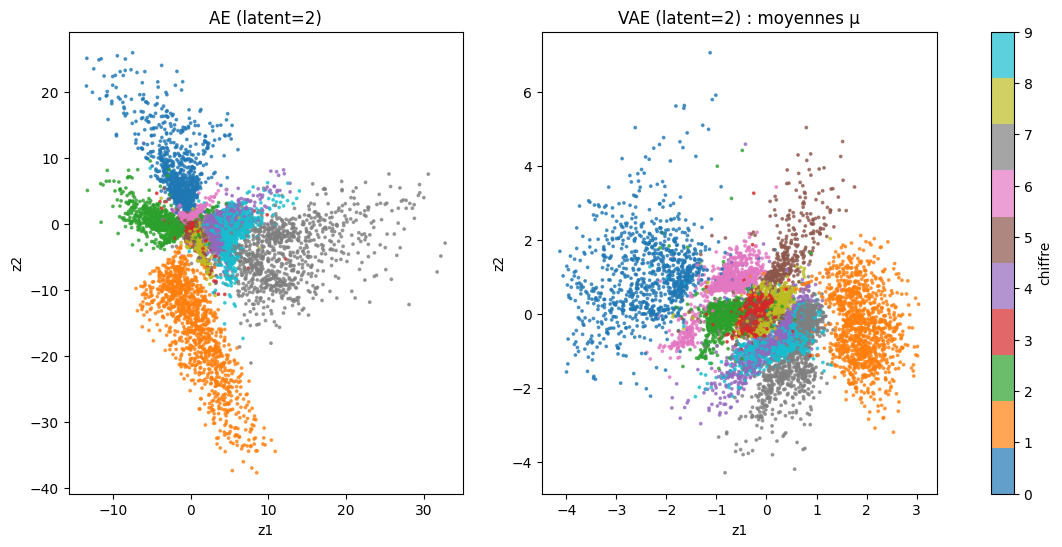

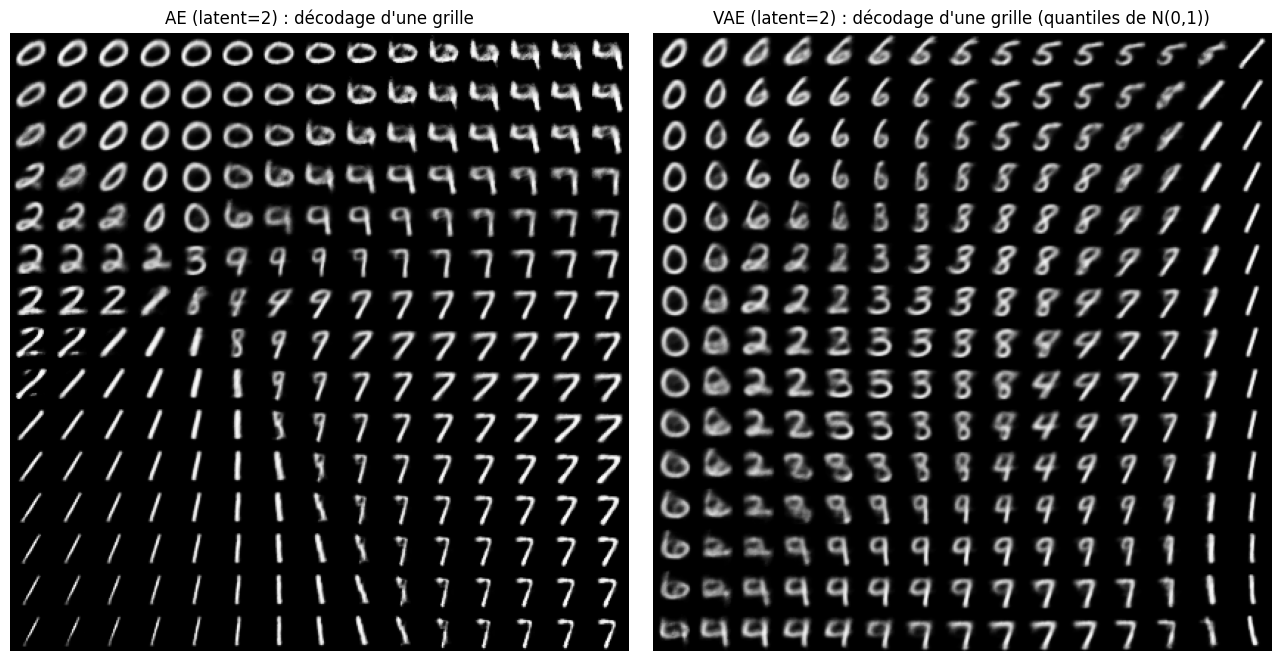

In [13]:
# espace latent à 2 dimensions
from torch.distributions import Normal

@torch.no_grad()
def codes_ae(m, X, bs=2000):
    m.eval(); return torch.cat([m.enc(x) for x in batches(X, bs, False)]).cpu().numpy()
@torch.no_grad()
def codes_vae(m, X, bs=2000):                      # moyennes μ du VAE
    m.eval(); return torch.cat([m.encode(x)[0] for x in batches(X, bs, False)]).cpu().numpy()

zA, zV, yl = codes_ae(model_ae2, Xte), codes_vae(model_vae2, Xte), yte.cpu().numpy()

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
for a, z, title in [(ax[0], zA, "AE (latent=2)"), (ax[1], zV, "VAE (latent=2) : moyennes μ")]:
    sc = a.scatter(z[:, 0], z[:, 1], c=yl, cmap="tab10", s=3, alpha=0.7)
    a.set(title=title, xlabel="z1", ylabel="z2")
fig.colorbar(sc, ax=ax, ticks=range(10)).set_label("chiffre")
plt.savefig(f"{OUT_DIR}/latent_scatter.png", dpi=150, bbox_inches="tight"); plt.show()

@torch.no_grad()
def decode_grid(dec, zs1, zs2):
    n = len(zs1); canvas = np.zeros((len(zs2) * 28, n * 28))
    for i, z2 in enumerate(zs2[::-1]):             # haut de l'image = grandes valeurs de z2
        zz = torch.tensor([[z1, z2] for z1 in zs1], dtype=torch.float32, device=device)
        imgs = torch.sigmoid(dec(zz)).view(-1, 28, 28).cpu().numpy()
        for j in range(n): canvas[i*28:(i+1)*28, j*28:(j+1)*28] = imgs[j]
    return canvas

n = 15
g_vae = Normal(0.0, 1.0).icdf(torch.linspace(0.02, 0.98, n)).numpy()     # quantiles de N(0, 1)
g_a1 = np.linspace(*np.percentile(zA[:, 0], [1, 99]), n)                 # AE : plage des codes observés
g_a2 = np.linspace(*np.percentile(zA[:, 1], [1, 99]), n)
fig, ax = plt.subplots(1, 2, figsize=(13, 6.5))
ax[0].imshow(decode_grid(model_ae2.dec, g_a1, g_a2), cmap="gray"); ax[0].set_title("AE (latent=2) : décodage d'une grille")
ax[1].imshow(decode_grid(model_vae2.dec, g_vae, g_vae), cmap="gray"); ax[1].set_title("VAE (latent=2) : décodage d'une grille (quantiles de N(0,1))")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/latent_decoded_grid.png", dpi=150); plt.show()

,modèle,accuracy k-NN (k=5)
0,AE latent=2,0.7860
1,VAE latent=2,0.7551
2,AE latent=32,0.9707
3,VAE latent=32,0.9572


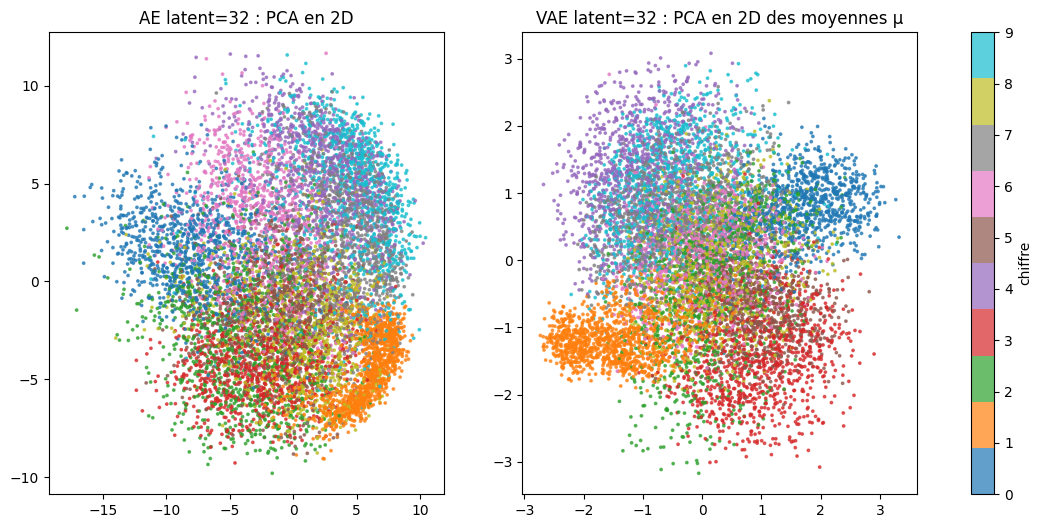

In [14]:
# mesure k-NN et PCA des modèles à 32 dimensions
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA

def knn_acc(f, m):
    Ztr, Zte = f(m, Xtr[:20000]), f(m, Xte)
    clf = KNeighborsClassifier(n_neighbors=5, n_jobs=-1).fit(Ztr, ytr[:20000].cpu().numpy())
    return clf.score(Zte, yl)

knn_df = pd.DataFrame({
    "modèle": ["AE latent=2", "VAE latent=2", f"AE latent={LAT_AE}", f"VAE latent={LAT_VAE}"],
    "accuracy k-NN (k=5)": [knn_acc(codes_ae, model_ae2), knn_acc(codes_vae, model_vae2),
                            knn_acc(codes_ae, model_ae), knn_acc(codes_vae, model_vae)]}).round(4)
display(knn_df); knn_df.to_csv(f"{OUT_DIR}/latent_knn.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
for a, z, title in [(ax[0], codes_ae(model_ae, Xte), f"AE latent={LAT_AE} : PCA en 2D"),
                    (ax[1], codes_vae(model_vae, Xte), f"VAE latent={LAT_VAE} : PCA en 2D des moyennes μ")]:
    p = PCA(2, random_state=SEED).fit_transform(z)
    sc = a.scatter(p[:, 0], p[:, 1], c=yl, cmap="tab10", s=3, alpha=0.7); a.set_title(title)
fig.colorbar(sc, ax=ax, ticks=range(10)).set_label("chiffre")
plt.savefig(f"{OUT_DIR}/latent_pca.png", dpi=150, bbox_inches="tight"); plt.show()

In [15]:
# archive des résultats, sans les poids
import zipfile
with zipfile.ZipFile("/kaggle/working/results_01.zip", "w") as z:
    for f in sorted(glob.glob(f"{OUT_DIR}/*")):
        if not f.endswith(".pt"): z.write(f, os.path.basename(f))
print(sorted(os.listdir(OUT_DIR)))

['ae_best.pt', 'ae_curves.png', 'ae_grid.csv', 'ae_latent2.pt', 'ae_reconstructions.png', 'generation_ae_vs_vae.png', 'latent_decoded_grid.png', 'latent_knn.csv', 'latent_pca.png', 'latent_scatter.png', 'results_ae.json', 'results_vae.json', 'vae_best.pt', 'vae_curves.png', 'vae_grid.csv', 'vae_latent2.pt', 'vae_reconstructions.png']
